# Exploratory data analysis

Documentation and morphology code corrected after review. Corrected morphology cells need a fresh run on Kaggle; other saved outputs are historical observations. Model, preprocessing and validation strategy choices remain open.


Data Directory: /kaggle/input/competitions/filament-segmentation-2026/MAGFiLO_1.0_Kaggle_2026
Annotation File Found: /kaggle/input/competitions/filament-segmentation-2026/MAGFiLO_1.0_Kaggle_2026/train/MAGFiLO_1.0_Annotations_kaggle2026_train.json
Number of images in train_images: 707
Number of images in test_images: 180


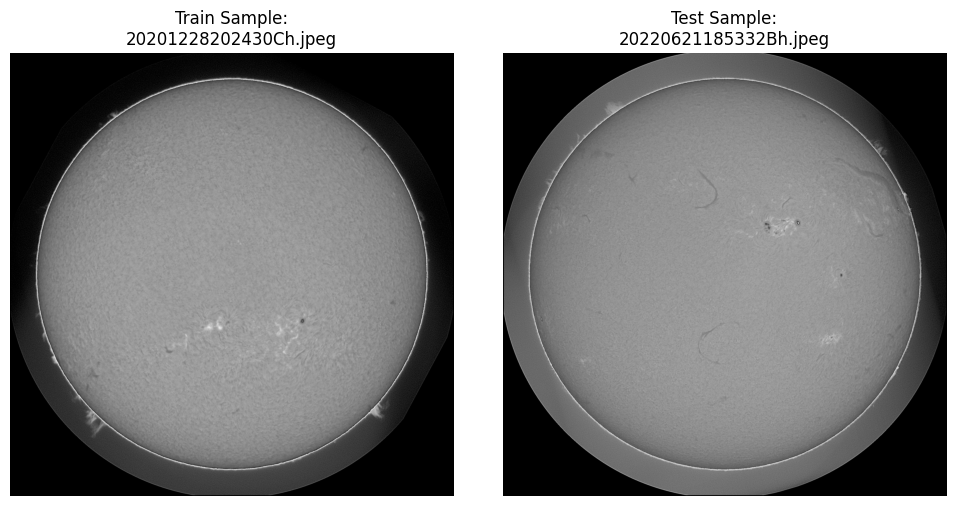

In [4]:
import os
import glob
import json
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm import tqdm
from pycocotools import mask as mask_utils

# Corrected paths based on your Kaggle directory structure
DATA_DIR = "/kaggle/input/competitions/filament-segmentation-2026/MAGFiLO_1.0_Kaggle_2026"
TRAIN_IMAGES_DIR = os.path.join(DATA_DIR, "train/train_images")
TEST_IMAGES_DIR = os.path.join(DATA_DIR, "test/test_images")

# Find the annotation JSON file dynamically
json_files = glob.glob(os.path.join(DATA_DIR, "train/*.json"))
ANNOTATION_JSON = json_files[0] if json_files else None

print(f"Data Directory: {DATA_DIR}")
print(f"Annotation File Found: {ANNOTATION_JSON}")

# 1. Count images in each folder
train_images = glob.glob(os.path.join(TRAIN_IMAGES_DIR, "*.jpeg")) + glob.glob(os.path.join(TRAIN_IMAGES_DIR, "*.jpg"))
test_images = glob.glob(os.path.join(TEST_IMAGES_DIR, "*.jpeg")) + glob.glob(os.path.join(TEST_IMAGES_DIR, "*.jpg"))

print(f"Number of images in train_images: {len(train_images)}")
print(f"Number of images in test_images: {len(test_images)}")

# 2. Display 1 sample image from each folder
fig, axes = plt.subplots(1, 2, figsize=(10, 5))

# Plot Train Sample
if train_images:
    sample_train = cv2.imread(train_images[0], cv2.IMREAD_GRAYSCALE)
    axes[0].imshow(sample_train, cmap='gray')
    axes[0].set_title(f"Train Sample:\n{os.path.basename(train_images[0])}")
    axes[0].axis('off')
else:
    axes[0].set_title("No Train Images Found")

# Plot Test Sample
if test_images:
    sample_test = cv2.imread(test_images[0], cv2.IMREAD_GRAYSCALE)
    axes[1].imshow(sample_test, cmap='gray')
    axes[1].set_title(f"Test Sample:\n{os.path.basename(test_images[0])}")
    axes[1].axis('off')
else:
    axes[1].set_title("No Test Images Found")

plt.tight_layout()
plt.show()

### 1. Environment Setup and Dataset Path Configuration

This cell imports the necessary Python libraries for computer vision, data manipulation, and COCO-style mask handling, and establishes the correct directory paths for the competition files nested inside the Kaggle environment.

* **Libraries Imported:**
  * `os` & `glob`: For directory traversal and file path matching.
  * `cv2`: OpenCV for reading and processing 8-bit grayscale solar images.
  * `numpy` & `pandas`: For tensor/array operations and building the submission data frame.
  * `pycocotools.mask`: Essential utility for encoding and decoding Run-Length Encoded (RLE) segmentation masks.
* **Path Resolution:** 
  * Points directly to the competition's nested root directory (`/kaggle/input/competitions/filament-segmentation-2026/MAGFiLO_1.0_Kaggle_2026`).
  * Dynamically uses `glob` to locate the training COCO JSON file without hardcoding its exact filename.

In [6]:
import os
import json
import glob
import cv2
import numpy as np
import pandas as pd
from tqdm import tqdm
from pycocotools import mask as mask_utils

# Corrected paths based on your Kaggle directory structure
DATA_DIR = "/kaggle/input/competitions/filament-segmentation-2026/MAGFiLO_1.0_Kaggle_2026"
TRAIN_IMAGES_DIR = os.path.join(DATA_DIR, "train/train_images")
TEST_IMAGES_DIR = os.path.join(DATA_DIR, "test/test_images")

# Find the annotation JSON file dynamically
json_files = glob.glob(os.path.join(DATA_DIR, "train/*.json"))
ANNOTATION_JSON = json_files[0] if json_files else None

print(f"Data Directory: {DATA_DIR}")
print(f"Annotation File Found: {ANNOTATION_JSON}")

Data Directory: /kaggle/input/competitions/filament-segmentation-2026/MAGFiLO_1.0_Kaggle_2026
Annotation File Found: /kaggle/input/competitions/filament-segmentation-2026/MAGFiLO_1.0_Kaggle_2026/train/MAGFiLO_1.0_Annotations_kaggle2026_train.json


### 2. Loading and Inspecting COCO-Style Annotations

This cell loads the training annotation file into memory and performs a structural sanity check to ensure the dataset is properly linked.

* **JSON Parsing:** Opens the discovered training JSON file and loads it as a standard Python dictionary (`coco_data`).
* **COCO Schema Inspection:** 
  * Prints top-level keys to confirm standard COCO keys (`images`, `annotations`, `categories`).
  * Counts total records to verify that training metadata matches the expected scale.
* **Safety Check:** Includes a conditional check to alert you immediately if the annotation file path resolves to `None`.

In [7]:
if ANNOTATION_JSON:
    with open(ANNOTATION_JSON, "r") as f:
        coco_data = json.load(f)
    
    print("COCO Keys:", list(coco_data.keys()))
    print(f"Total Images in JSON: {len(coco_data.get('images', []))}")
    print(f"Total Filament Annotations: {len(coco_data.get('annotations', []))}")
    
    # Optional: Print a quick sample of the categories or first image info
    if 'categories' in coco_data:
        print(f"Categories: {coco_data['categories']}")
else:
    print("Warning: Annotation JSON not found. Please check the dataset path.")

COCO Keys: ['info', 'licenses', 'categories', 'images', 'annotations']
Total Images in JSON: 1154
Total Filament Annotations: 8199
Categories: [{'supercategory': 'filament', 'id': 1, 'name': 'Left'}, {'supercategory': 'filament', 'id': 2, 'name': 'Right'}, {'supercategory': 'filament', 'id': 3, 'name': 'Unidentifiable'}, {'supercategory': 'filament', 'id': 4, 'name': 'Ambiguous'}]


### 3. Pixel Intensity and Contrast Distribution Analysis

This cell analyzes the pixel characteristics of the solar images. Since GONG H-alpha observations measure solar brightness and vary based on atmospheric conditions and instrument calibration, checking pixel intensity distributions helps determine:
* Whether the images share a uniform brightness scale.
* Whether contrast stretching or normalization (e.g., Min-Max scaling or CLAHE) is worth testing before feeding images into a neural network.

Sampled 5 images for pixel inspection:
  - Min Pixel Value Range: 0 to 0
  - Max Pixel Value Range: 229 to 250
  - Mean Pixel Value Range: 84.30


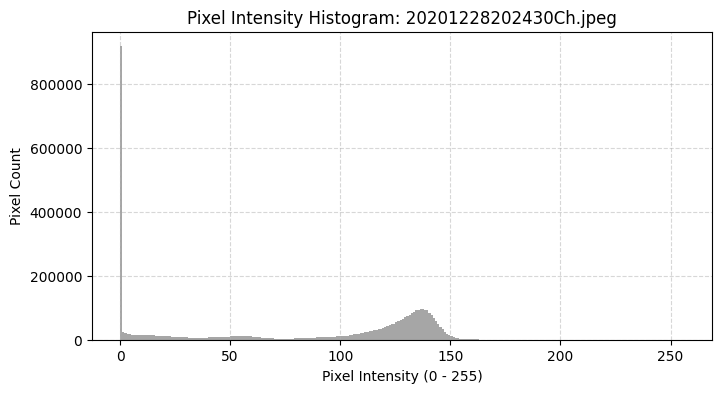

In [9]:
import matplotlib.pyplot as plt
import numpy as np
import cv2
import glob
import os

# Sample a few train images to check pixel statistics
sample_paths = glob.glob(os.path.join(TRAIN_IMAGES_DIR, "*.jpeg"))[:5]

pixel_mins = []
pixel_maxs = []
pixel_means = []

for path in sample_paths:
    img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    if img is not None:
        pixel_mins.append(img.min())
        pixel_maxs.append(img.max())
        pixel_means.append(img.mean())

print(f"Sampled {len(sample_paths)} images for pixel inspection:")
print(f"  - Min Pixel Value Range: {min(pixel_mins)} to {max(pixel_mins)}")
print(f"  - Max Pixel Value Range: {min(pixel_maxs)} to {max(pixel_maxs)}")
print(f"  - Mean Pixel Value Range: {np.mean(pixel_means):.2f}")

# Plot a histogram of pixel intensities for one sample image
if sample_paths:
    sample_img = cv2.imread(sample_paths[0], cv2.IMREAD_GRAYSCALE)
    plt.figure(figsize=(8, 4))
    plt.hist(sample_img.ravel(), bins=256, range=[0, 256], color='gray', alpha=0.7)
    plt.title(f"Pixel Intensity Histogram: {os.path.basename(sample_paths[0])}")
    plt.xlabel("Pixel Intensity (0 - 255)")
    plt.ylabel("Pixel Count")
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.show()

### 5. Station-Specific Comparison of Background and Image Quality

This cell groups the training images by their GONG observatory station source (extracted from the filename suffixes like `Lh`, `Mh`, `Th`, etc.), counts how many images belong to each station, and plots a side-by-side sample to inspect any visual differences in background noise or contrast across telescopes.

Image counts per GONG station:
  - Station 'Bh': 118 images
  - Station 'Ch': 125 images
  - Station 'Lh': 127 images
  - Station 'Mh': 125 images
  - Station 'Th': 110 images
  - Station 'Uh': 102 images


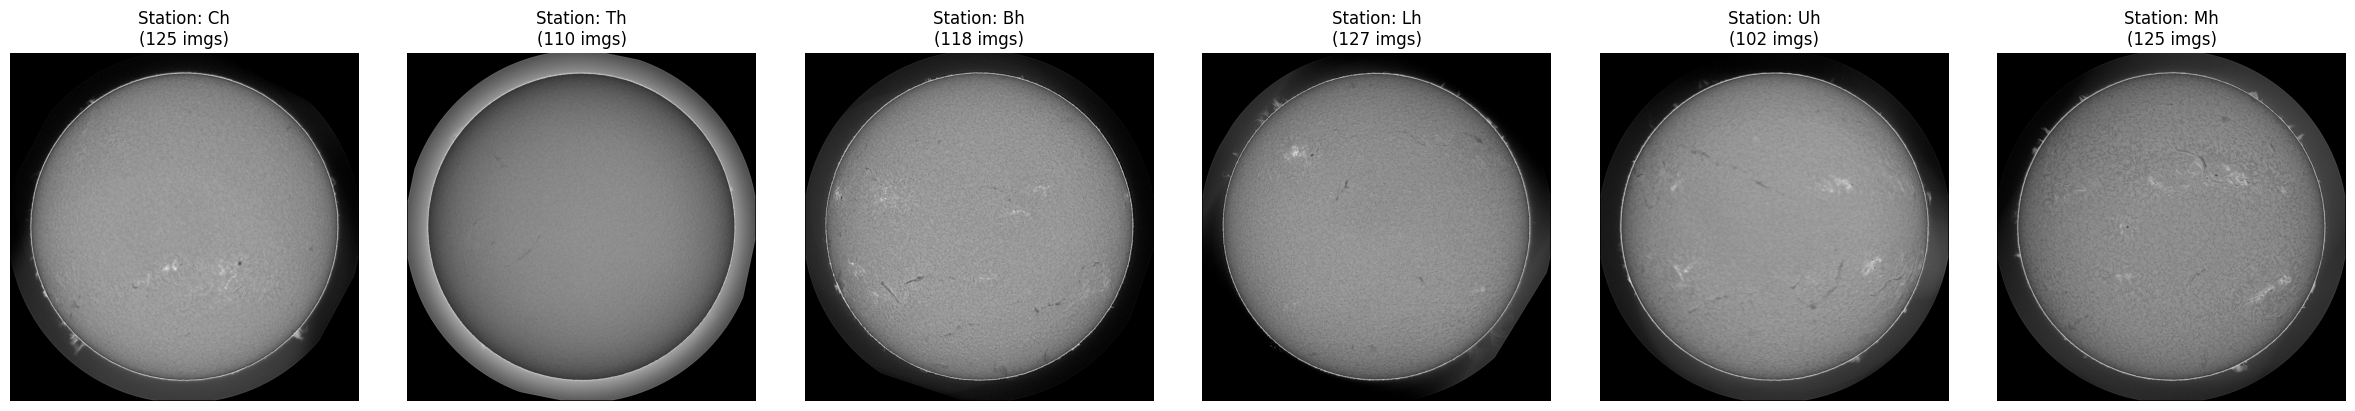

In [12]:
import os
import glob
import cv2
import numpy as np
import matplotlib.pyplot as plt
from collections import defaultdict

# Gather all train images
train_images = glob.glob(os.path.join(TRAIN_IMAGES_DIR, "*.jpeg")) + glob.glob(os.path.join(TRAIN_IMAGES_DIR, "*.jpg"))

# Group images by station suffix (e.g., 'Lh', 'Mh', 'Th', 'Ch', 'Bh', 'Uh')
station_dict = defaultdict(list)
for path in train_images:
    filename = os.path.basename(path)
    # Extract station code (characters right before '.jpeg' or '.jpg')
    station_code = filename.split('.')[0][-2:] 
    station_dict[station_code].append(path)

print("Image counts per GONG station:")
for station, paths in sorted(station_dict.items()):
    print(f"  - Station '{station}': {len(paths)} images")

# Plot one sample image from each available station
stations = list(station_dict.keys())
fig, axes = plt.subplots(1, len(stations), figsize=(4 * len(stations), 4))

if len(stations) == 1:
    axes = [axes]

for ax, station in zip(axes, stations):
    sample_path = station_dict[station][0]
    img = cv2.imread(sample_path, cv2.IMREAD_GRAYSCALE)
    
    ax.imshow(img, cmap='gray')
    ax.set_title(f"Station: {station}\n({len(station_dict[station])} imgs)")
    ax.axis('off')

plt.tight_layout()
plt.show()

### GONG stations and validation considerations

GONG (Global Oscillation Network Group) operates six observing sites to observe the Sun as continuously as possible. Continuous coverage is an aim, not a guarantee.

| Code | Observatory |
| --- | --- |
| Bh | Big Bear, California, USA |
| Ch | Cerro Tololo, Chile |
| Lh | Learmonth, Australia |
| Mh | Mauna Loa, Hawaii, USA |
| Th | Teide, Canary Islands, Spain |
| Uh | Udaipur, Rajasthan, India |

Source: https://nso.edu/telescopes/nisp/gong/

Station samples suggest differences worth measuring. A single sample cannot establish a station-wide artifact or its physical cause.

Before validation, group all annotation records with the same source filename together. Nearby observations, including those from different stations, may show the same structures, so temporal grouping also needs discussion. Station stratification can help balance groups but does not prevent leakage by itself.

Normalization, disk masking and augmentation are candidate experiments. Verify that any mask preserves annotated filaments, especially near the limb, before applying it. No split or preprocessing strategy has been selected yet.


### 4. Solar Disk Framing and Scale Consistency Check

This cell checks whether the sun's disk is equally zoomed in and centered across different images. Because GONG data comes from multiple ground-based stations, minor variations in optical zoom or alignment could cause the solar radius or center coordinates to shift. 

* **Method:** It thresholds each image to separate the bright solar disk from the black background of space, finds the outer contour, and computes the minimum enclosing circle's radius and center coordinates.

In [10]:
import cv2
import numpy as np
import glob
import os

# Sample a larger batch of train images to check radius and center consistency
sample_paths = glob.glob(os.path.join(TRAIN_IMAGES_DIR, "*.jpeg"))[:30]

radii = []
centers = []

for path in sample_paths:
    img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    if img is None:
        continue
        
    # Threshold to separate the solar disk from the black background of space
    _, thresh = cv2.threshold(img, 10, 255, cv2.THRESH_BINARY)
    
    # Find contours of the solar disk
    contours, _ = cv2.findContours(thresh, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    if contours:
        # Assume the largest contour is the solar disk
        largest_contour = max(contours, key=cv2.contourArea)
        ((x, y), radius) = cv2.minEnclosingCircle(largest_contour)
        radii.append(radius)
        centers.append((x, y))

if radii:
    print(f"Successfully inspected {len(radii)} images:")
    print(f"  - Solar Radius Range: {min(radii):.2f} to {max(radii):.2f} pixels")
    print(f"  - Mean Solar Radius: {np.mean(radii):.2f} pixels")
    print(f"  - X-Center Range: {min([c[0] for c in centers]):.2f} to {max([c[0] for c in centers]):.2f} pixels")
    print(f"  - Y-Center Range: {min([c[1] for c in centers]):.2f} to {max([c[1] for c in centers]):.2f} pixels")
else:
    print("No valid contours found in the sample.")

Successfully inspected 30 images:
  - Solar Radius Range: 1029.97 to 1036.47 pixels
  - Mean Solar Radius: 1035.59 pixels
  - X-Center Range: 1021.12 to 1023.61 pixels
  - Y-Center Range: 1022.91 to 1061.50 pixels


### Preliminary disk geometry observations

The saved run reports enclosing-circle radii of approximately 1,030–1,036 pixels and a vertical center range of approximately 1,023–1,062 pixels in a sample of 30 images.

These are estimates from a brightness threshold and the largest contour, not calibrated solar radii. A radius above 1,024 pixels in a 2,048-pixel frame needs visual inspection for clipped disks, borders, or threshold artifacts. The sample does not establish dataset-wide geometry consistency.

Inspect circle overlays across stations before choosing a disk mask. These results do not establish whether multi-scale processing or spatial augmentation improves segmentation.


### 5. Image Resolution and Integrity Distribution Check

#### Key Purpose
* **Dimension Consistency Verification:** Checking whether *all* training and test images share the identical expected resolution (2,048×2,048 pixels) to prevent unexpected tensor shape mismatches or DataLoader crashes during training.
* **Corrupted Image Detection:** Scanning for any unreadable or corrupted files across the directory.

#### Modeling Consequences
* **Fixed-Size Batching:** Confirmed uniform resolutions allow efficient batching without requiring dynamic resizing or padding collate functions.
* **Pipeline Stability:** Validates that downstream cropping, normalization, and tensor conversions can assume a consistent input shape across the entire dataset.

In [13]:
import os
import glob
from collections import Counter
import cv2

def check_resolutions(image_dir, name="Dataset"):
    image_paths = glob.glob(os.path.join(image_dir, "*.jpeg")) + glob.glob(os.path.join(image_dir, "*.jpg"))
    resolutions = Counter()
    
    for path in image_paths:
        # Read image header/shape without fully loading pixel data if preferred, 
        # but cv2.imread is fast enough for 2048x2048
        img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
        if img is not None:
            resolutions[img.shape] += 1
        else:
            resolutions["Corrupted/Unreadable"] += 1
            
    print(f"{name} Resolution Distribution:")
    for res, count in resolutions.items():
        print(f"  - {res}: {count} images")

# Run checks
check_resolutions(TRAIN_IMAGES_DIR, "Train Images")
check_resolutions(TEST_IMAGES_DIR, "Test Images")

Train Images Resolution Distribution:
  - (2048, 2048): 707 images
Test Images Resolution Distribution:
  - (2048, 2048): 180 images


### 6. Target Annotation and Label Distribution Analysis

#### Key Purpose
* **Instance Count Evaluation:** Checking how many filament structures typically appear on a single solar disk to understand label density.
* **Size/Area Distribution:** Measuring the pixel area range of the annotations to ensure models can handle both small, fragmented filament strands and large, sprawling magnetic loops.

#### Modeling Consequences
* **Loss Function Design:** Knowing the relative pixel coverage of thin filaments versus the massive background helps determine appropriate class-imbalance weighting or loss choices (e.g., combining BCE and Dice/Tversky loss).
* **Anchor/Mask Sizing:** Helps motivate experiments with multi-scale feature maps to capture tiny filament structures across a 2,048×2,048 spatial grid.

Looking for annotations at: /kaggle/input/competitions/filament-segmentation-2026/MAGFiLO_1.0_Kaggle_2026/train/MAGFiLO_1.0_Annotations_kaggle2026_train.json

--- Annotation Statistics ---
Total Images in JSON: 1154
Total Filament Annotations: 8199
Average Filaments per Image: 7.10
Filament Area Range: 9.0 to 37739.0 pixels²
Median Filament Area: 1228.00 pixels²


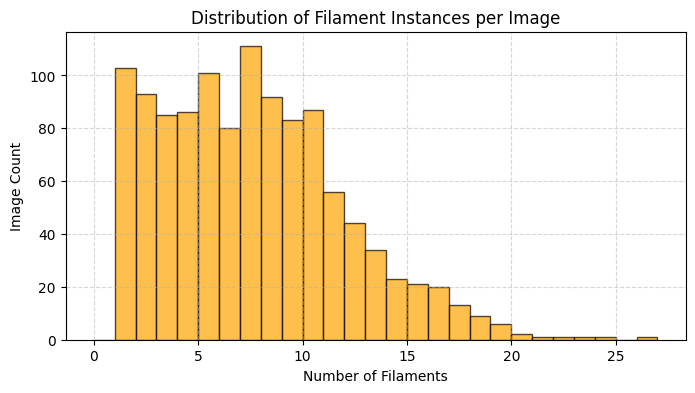

In [16]:
import json
import os
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter

# TRAIN_IMAGES_DIR is already defined in your earlier cells as ".../train/images" (or similar)
# Let's derive the train root folder from it
if 'TRAIN_IMAGES_DIR' in globals():
    TRAIN_DIR = os.path.dirname(TRAIN_IMAGES_DIR)
else:
    TRAIN_DIR = "./train"

# Use the exact annotation filename shown in your Kaggle input panel
annotation_file = os.path.join(TRAIN_DIR, "MAGFiLO_1.0_Annotations_kaggle2026_train.json")

print(f"Looking for annotations at: {annotation_file}")

if os.path.exists(annotation_file):
    with open(annotation_file, 'r') as f:
        coco_data = json.load(f)
        
    images_info = {img['id']: img['file_name'] for img in coco_data['images']}
    annotations = coco_data['annotations']
    
    # Count annotations per image
    img_anno_counts = Counter([anno['image_id'] for anno in annotations])
    
    # Calculate mask sizes (areas in pixels)
    anno_areas = [anno['area'] for anno in annotations]
    
    print(f"\n--- Annotation Statistics ---")
    print(f"Total Images in JSON: {len(images_info)}")
    print(f"Total Filament Annotations: {len(annotations)}")
    print(f"Average Filaments per Image: {np.mean(list(img_anno_counts.values())):.2f}")
    print(f"Filament Area Range: {min(anno_areas)} to {max(anno_areas)} pixels²")
    print(f"Median Filament Area: {np.median(anno_areas):.2f} pixels²")
    
    # Plot distribution of filament counts per image
    plt.figure(figsize=(8, 4))
    plt.hist(list(img_anno_counts.values()), bins=range(0, max(img_anno_counts.values())+2), color='orange', alpha=0.7, edgecolor='black')
    plt.title("Distribution of Filament Instances per Image")
    plt.xlabel("Number of Filaments")
    plt.ylabel("Image Count")
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.show()
else:
    print(f"Annotation file not found at {annotation_file}. Please check path variables.")

### Annotation counts and size distribution

The saved run reports 707 training image files, 1,154 image/annotator records in the JSON, and 8,199 filament annotations. The 1,154 records must not be described as 1,154 distinct photographs. Reconcile unique filenames and repeated annotator records before splitting or reporting image-level statistics.

The saved annotation areas range from 9 to 37,739 pixels², with a median of 1,228 pixels². The reported mean of 7.10 annotations is per annotated JSON record, not necessarily per unique photograph. The current counter excludes records with zero annotations, if any exist.

Size variation motivates checking performance on small and large objects. It does not by itself establish a required architecture or loss function. Evaluate candidate approaches using held-out data and the organizer's instance-level evaluator.


### 8. Ground-Truth Filament Mask Overlay Verification

This cell decodes the COCO annotations from the training annotation JSON and overlays the ground-truth filament masks onto the corresponding solar images. Visualizing masks directly on the raw solar disks allows us to inspect annotation alignment, check how fine/thin the filament boundaries are, and confirm mask rasterization before feeding data into the segmentation network.

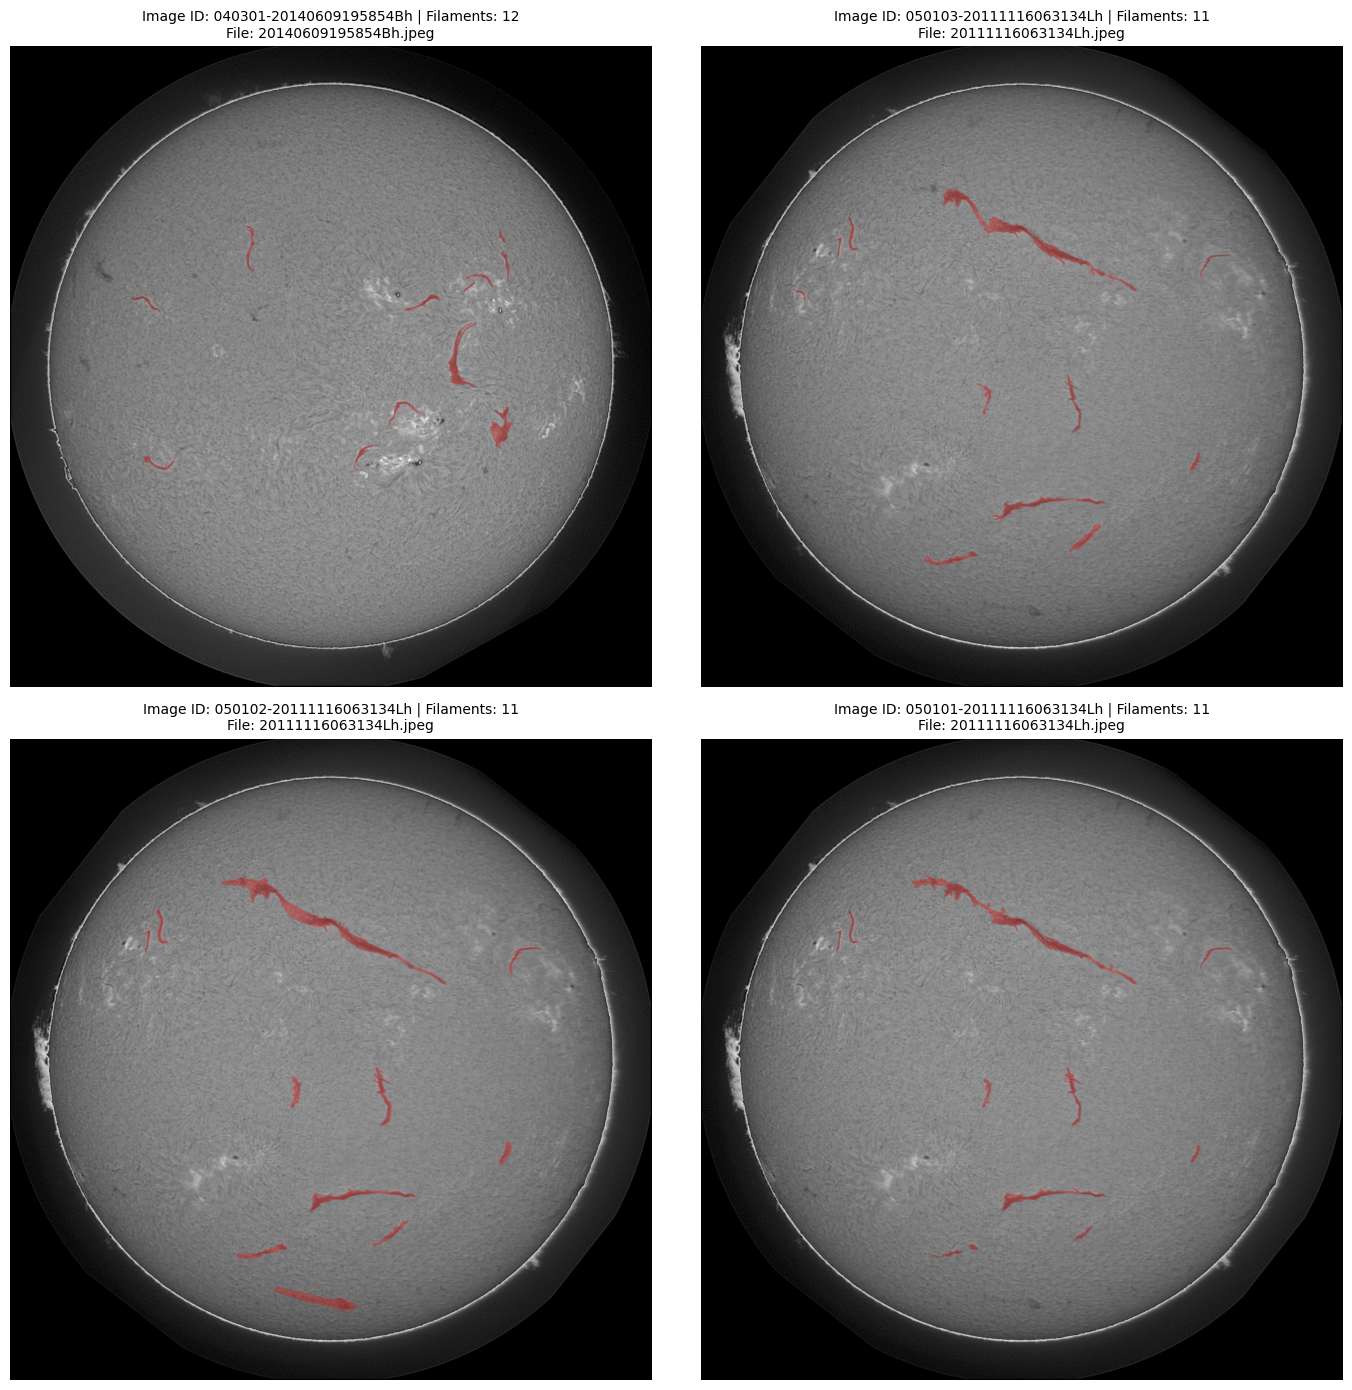

In [18]:
import os
import json
import cv2
import numpy as np
import matplotlib.pyplot as plt
from pycocotools import mask as maskUtils

# Load COCO annotations
annotation_file = os.path.join(TRAIN_DIR, "MAGFiLO_1.0_Annotations_kaggle2026_train.json")

with open(annotation_file, 'r') as f:
    coco_data = json.load(f)

# Build mappings
images_by_id = {img['id']: img for img in coco_data['images']}
annotations_by_img = {}
for anno in coco_data['annotations']:
    img_id = anno['image_id']
    if img_id not in annotations_by_img:
        annotations_by_img[img_id] = []
    annotations_by_img[img_id].append(anno)

# Function to decode segmentation to binary mask
def anno_to_mask(anno, height, width):
    seg = anno['segmentation']
    if isinstance(seg, list):  # Polygon format
        rles = maskUtils.frPyObjects(seg, height, width)
        rle = maskUtils.merge(rles)
    elif isinstance(seg, dict) and 'counts' in seg:  # RLE format
        rle = seg
    else:
        return np.zeros((height, width), dtype=np.uint8)
    return maskUtils.decode(rle)

# Select a few images with varying numbers of filaments to visualize
sample_img_ids = [img_id for img_id, annos in annotations_by_img.items() if len(annos) >= 3][:4]

fig, axes = plt.subplots(2, 2, figsize=(14, 14))
axes = axes.flatten()

for ax, img_id in zip(axes, sample_img_ids):
    img_info = images_by_id[img_id]
    img_path = os.path.join(TRAIN_IMAGES_DIR, img_info['file_name'])
    
    img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
    if img is None:
        continue
    
    height, width = img.shape
    combined_mask = np.zeros((height, width), dtype=np.uint8)
    
    annos = annotations_by_img[img_id]
    for anno in annos:
        m = anno_to_mask(anno, height, width)
        combined_mask = np.maximum(combined_mask, m)
    
    # Convert grayscale image to RGB for overlay
    img_rgb = cv2.cvtColor(img, cv2.COLOR_GRAY2RGB)
    
    # Create semi-transparent red overlay for filaments
    overlay = img_rgb.copy()
    overlay[combined_mask == 1] = [255, 0, 0]  # Red mask
    
    # Blend overlay with original image
    visualized = cv2.addWeighted(img_rgb, 0.7, overlay, 0.3, 0)
    
    ax.imshow(visualized)
    ax.set_title(f"Image ID: {img_id} | Filaments: {len(annos)}\nFile: {img_info['file_name']}", fontsize=10)
    ax.axis('off')

plt.tight_layout()
plt.show()

### Interpretation of mask overlays

The displayed examples allow a preliminary check of polygon rasterization and alignment. A few examples do not establish perfect alignment or pipeline readiness across the dataset.

The combined binary mask in this cell is for visualization only. Preserve each annotation's individual mask and identity for instance-level training targets and evaluation. A combined mask cannot represent which neighboring pixels belong to different filaments.

Before training, check empty and malformed masks, dimensions, image-to-annotation links and encoding round trips. Finalize a leakage-aware validation plan separately.


### 9. Filament morphology and elongation

Ellipse axis ratio describes elongation, not physical filament length. A curved or branched object may be poorly summarized by an ellipse.

The following cell measures one ellipse per nonempty annotation mask, using points from all external contours together. Perimeter is the sum of external contour perimeters. Masks with too few boundary points or invalid ellipse axes retain an undefined ratio rather than being assigned a shape class.

Repeated annotator records remain separate observations. Results therefore describe annotation masks, not necessarily independent physical filaments. Architecture and loss choices remain experiments.


In [ ]:
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

morphology_rows = []
for img_id, annos in annotations_by_img.items():
    info = images_by_id[img_id]
    for anno in annos:
        mask = anno_to_mask(anno, info['height'], info['width']).astype(np.uint8)
        ratio = np.nan
        contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        perimeter = sum(cv2.arcLength(c, True) for c in contours)
        if contours:
            points = np.concatenate(contours, axis=0)
            if len(points) >= 5:
                try:
                    _, axes, _ = cv2.fitEllipse(points)
                    major, minor = max(axes), min(axes)
                    if minor > 0 and np.isfinite(major) and np.isfinite(minor):
                        ratio = major / minor
                except cv2.error:
                    pass
        morphology_rows.append({
            'annotation_id': anno['id'], 'image_id': img_id,
            'aspect_ratio': ratio, 'perimeter': perimeter,
            'empty_mask': not bool(mask.any()),
        })

morphology = pd.DataFrame(morphology_rows, columns=[
    'annotation_id', 'image_id', 'aspect_ratio', 'perimeter', 'empty_mask'])
assert len(morphology) == len(coco_data['annotations'])
ratios = morphology['aspect_ratio'].dropna()
print('Annotation masks:', len(morphology))
print('Measurable axis ratios:', len(ratios))
print('Empty masks:', int(morphology['empty_mask'].sum()))
if len(ratios):
    print(f'Mean axis ratio: {ratios.mean():.2f}')
    print(f'Maximum axis ratio: {ratios.max():.2f}')
    plt.figure(figsize=(8, 4))
    plt.hist(ratios, bins=50)
    plt.xlabel('Fitted ellipse major/minor axis ratio')
    plt.ylabel('Annotation count')
    plt.title('Annotation mask elongation')
    plt.show()


### Morphology results require a fresh run

The previous implementation measured separate contours rather than one result per annotation. Its saved mean of 3.65 and maximum of 51.14 are not valid per-annotation summaries and have been removed from the results cell.

The corrected cell above has not been rerun on the competition data. Inspect fitted ellipses for curved and disconnected masks before interpreting new statistics. Elongation alone does not determine filament type, physical length, or an optimal loss function.


In [ ]:
# Exploratory shape categories, not physical filament lengths.
shape_rows = morphology.copy()
shape_rows['shape_group'] = np.where(
    shape_rows['aspect_ratio'].isna(), 'unmeasurable',
    np.where(shape_rows['aspect_ratio'] > 4.0, 'elongated', 'compact'))
counts = shape_rows['shape_group'].value_counts()
assert int(counts.sum()) == len(coco_data['annotations'])
print('Annotation counts by exploratory shape group:')
print(counts)
df_stats = pd.crosstab(shape_rows['image_id'], shape_rows['shape_group']).reindex(
    index=list(images_by_id), columns=['compact', 'elongated', 'unmeasurable'],
    fill_value=0)
print('Correlation across image/annotator records (not independent photographs):')
print(df_stats[['compact', 'elongated']].corr())


### 9.1 Compact and elongated annotations

An exploratory axis-ratio threshold of 4 separates compact from elongated masks. It is not a physical short/long classification and does not identify active-region or polar-crown filaments.

The previous contour-based totals (5,436 plus 2,793 = 8,229) exceeded the 8,199 annotations. Those counts and their correlation are withdrawn pending a fresh run. The corrected code counts each annotation once and reports unmeasurable or empty masks separately.

Co-occurrence does not establish a solar-cycle explanation or guarantee balanced validation folds. Validate grouped splits and evaluate any proposed loss or sampling choices experimentally.


### 10. Open questions for the next discussion

* [ ] Reconcile unique source images, repeated annotator records and zero-annotation records.
* [ ] Decide image/time grouping for validation, then assess station balance.
* [ ] Rerun corrected morphology cells and inspect ellipse fits and disk-circle overlays.
* [ ] Audit brightness on representative images across stations, separating solar-disk pixels from black background.
* [ ] Preserve individual masks and run the organizer's instance-level evaluator on a baseline.
* [ ] Treat image Y-position as a projected coordinate. Physical solar latitude needs disk geometry, orientation and viewing corrections.
* [ ] Keep magnetogram comparisons, if permitted, separate from model inputs. The competition overview restricts inference to supplied H-alpha images and training to permitted segmentation ground truth.
